<a href="https://colab.research.google.com/github/Arceus2006/AIML-project/blob/main/Data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'india-global-migration-dataset' dataset.
Dataset downloaded to: /kaggle/input/india-global-migration-dataset

Shape: (1323, 9)

Columns: ['Year', 'Destination_Country', 'Region', 'Column_Name', 'Value', 'Data_Type', 'Source_Name', 'Source_URL', 'Notes']

First 5 Rows
   Year Destination_Country         Region             Column_Name  \
0  2000                 USA  North America   Total_Indian_Migrants   
1  2000                 USA  North America      Permanent_Migrants   
2  2000                 USA  North America       Temporary_Workers   
3  2000                 USA  North America                Students   
4  2000                 USA  North America  Remittance_USD_Billion   

           Value Data_Type                              Source_Name  \
0      1,005,000      real      UN DESA International Migrant Stock   
1  NOT AVAILABLE      real                                      NaN   
2  NOT AVAILABLE      real                            

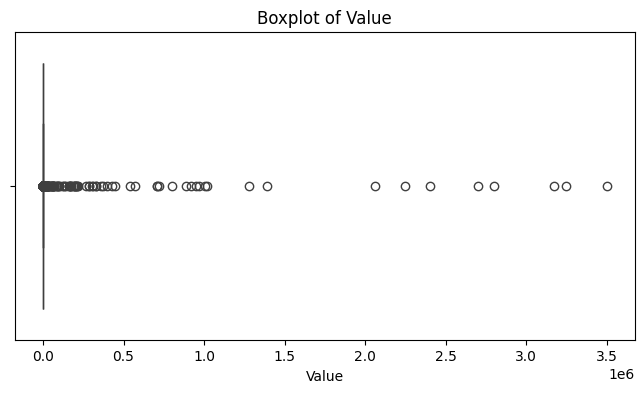

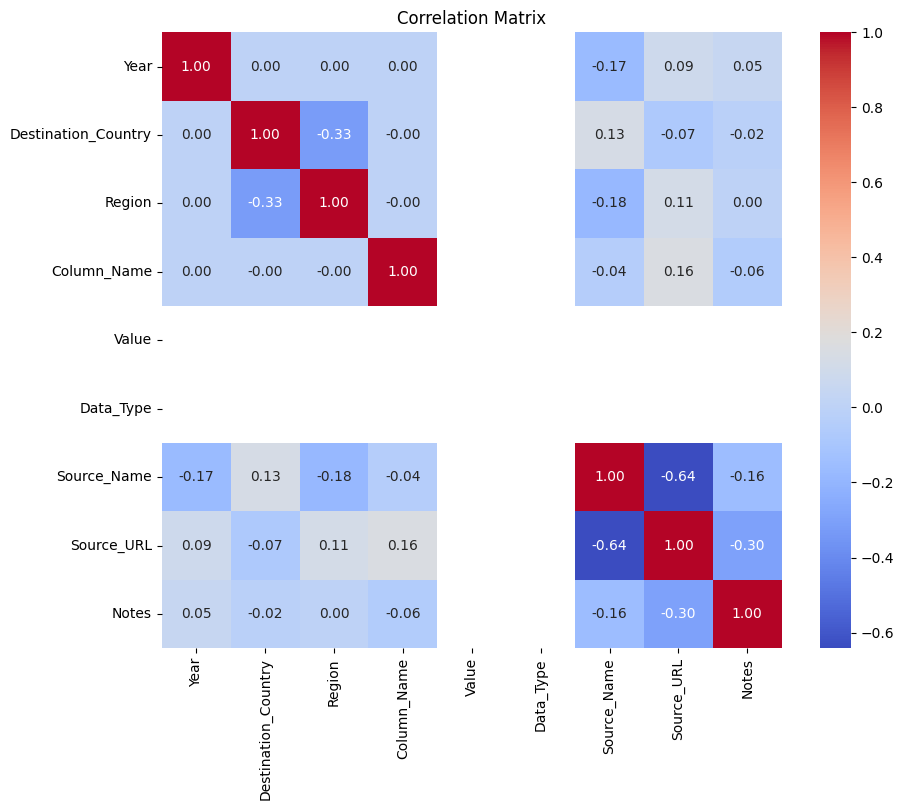

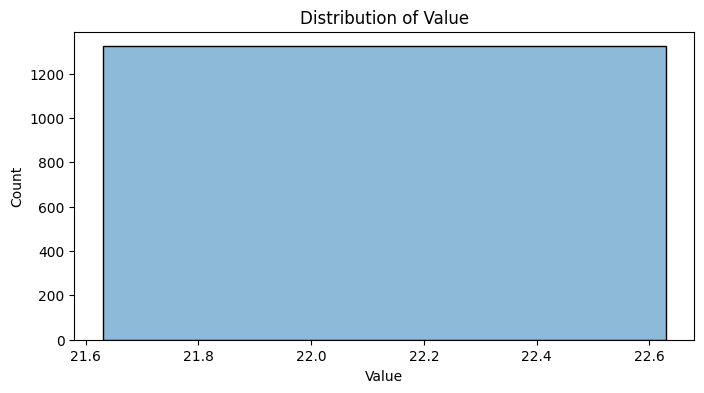

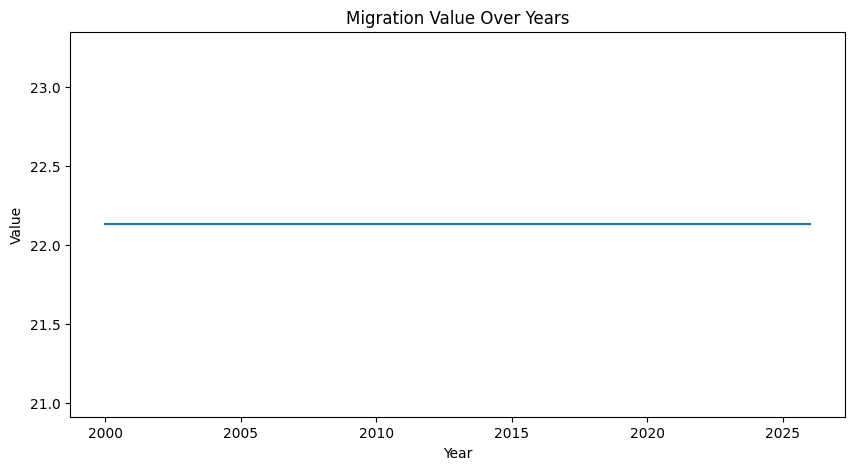


Final Shape: (1323, 11)
   Year  Destination_Country  Region  Column_Name  Value  Data_Type  \
0  2000                    6       3            5  22.13          0   
1  2000                    6       3            1  22.13          0   
2  2000                    6       3            4  22.13          0   
3  2000                    6       3            3  22.13          0   
4  2000                    6       3            2  22.13          0   

   Source_Name  Source_URL  Notes  Decade  High_Value  
0           41          18      9    2000           0  
1           43           0     29    2000           0  
2           43           0     29    2000           0  
3           43           0     29    2000           0  
4           45           1     31    2000           0  

Saved as: preprocessed_indian_overseas_migration.csv


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler


path = kagglehub.dataset_download("aryanmdev/india-global-migration-dataset")
print("Dataset downloaded to:", path)

file_path = os.path.join(path, "indian_overseas_migration_dataset.csv")
df = pd.read_csv(file_path)


print("\nShape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 Rows")
print(df.head())

print("\nDataset Info")
df.info()

print("\nSummary")
print(df.describe(include="all"))


print("\nMissing Values")
print(df.isnull().sum())

for col in df.select_dtypes(include="object").columns:
    if col != "Value":
        df[col] = df[col].fillna("Unknown")


print("\nDuplicate Rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# --
df["Value"] = (
    df["Value"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .replace("NOT AVAILABLE", np.nan)
)

df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
df["Value"] = df["Value"].fillna(df["Value"].median())

print("\nValue datatype:", df["Value"].dtype)

# --
df["Year"] = df["Year"].astype(int)

# --
categorical_cols = [
    "Destination_Country",
    "Region",
    "Column_Name",
    "Data_Type",
    "Source_Name",
    "Source_URL",
    "Notes"
]

encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col].astype(str))
    encoders[col] = encoder

print("\nCategorical columns encoded.")

# --
Q1 = df["Value"].quantile(0.25)
Q3 = df["Value"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Value"] < lower) | (df["Value"] > upper)]
print("Outliers in Value:", len(outliers))

plt.figure(figsize=(8,4))
sns.boxplot(x=df["Value"])
plt.title("Boxplot of Value")
plt.show()

# --
df["Value"] = df["Value"].clip(lower, upper)

# --
minmax_df = df.copy()
standard_df = df.copy()

mm = MinMaxScaler()
ss = StandardScaler()

minmax_df[["Value"]] = mm.fit_transform(df[["Value"]])
standard_df[["Value"]] = ss.fit_transform(df[["Value"]])

# --
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm",
            fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


# 12. Visualizations

plt.figure(figsize=(8,4))
sns.histplot(df["Value"], kde=True)
plt.title("Distribution of Value")
plt.show()

plt.figure(figsize=(10,5))
sns.lineplot(data=df, x="Year", y="Value")
plt.title("Migration Value Over Years")
plt.show()

# 13. Feature Engineering

df["Decade"] = (df["Year"] // 10) * 10

df["High_Value"] = (
    df["Value"] > df["Value"].median()
).astype(int)

# 14. Final Dataset-
print("\nFinal Shape:", df.shape)
print(df.head())


output = "preprocessed_indian_overseas_migration.csv"
df.to_csv(output, index=False)

print("\nSaved as:", output)
